# Localization label generation

Produces the curated marker labels used by every analysis (`labels/markers_curated.txt`), and summarizes how many labeled genes each cohort holds.

**Pipeline**
1. Read the marker proteins from Orre et al. (3,365 proteins, each assigned to one of four compartments: Cytosol, Mitochondria, Nucleus, Secretory).
2. MetaMass filter: remove markers whose compartment differs from the MetaMass annotation (Lund-Johansen et al.), grouped into the same four compartments. Markers absent from MetaMass are kept.
3. HPA filter: remove markers whose compartment is not among their Human Protein Atlas locations (main and additional). Only HPA entries with reliability Enhanced or Supported are used, and only locations that map to one of the four compartments (see `HPA_TO_COMPARTMENT`). Markers absent from HPA, with a lower reliability, or with no mapped location are kept.
4. Export the remaining markers (2,947 kept, 418 removed: 172 conflict with MetaMass only, 168 with HPA only, 78 with both). Labels are never changed, only removed, and the Orre order is kept. Every removed marker is listed with its Orre, MetaMass and HPA evidence.

## Set up

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn3

### Settings

In [2]:
label_path = 'labels/'
dataset_path = 'processed_datasets_prot_mrna/'

COMPARTMENTS = ['Cytosol', 'Mitochondria', 'Nucleus', 'Secretory']

# HPA reliability levels that are trusted enough to remove a marker.
HPA_RELIABILITY = ['Enhanced', 'Supported']

# HPA location -> compartment. Locations not listed here (for example centrosome or cell junctions) are ignored.
HPA_TO_COMPARTMENT = {
    'Nucleoplasm': 'Nucleus', 'Nucleoli': 'Nucleus', 'Nucleoli fibrillar center': 'Nucleus', 'Nucleoli rim': 'Nucleus',
    'Nuclear speckles': 'Nucleus', 'Nuclear membrane': 'Nucleus', 'Nuclear bodies': 'Nucleus',
    'Mitochondria': 'Mitochondria',
    'Cytosol': 'Cytosol', 'Microtubules': 'Cytosol',
    'Golgi apparatus': 'Secretory', 'Endoplasmic reticulum': 'Secretory', 'Plasma membrane': 'Secretory',
    'Vesicles': 'Secretory', 'Peroxisomes': 'Secretory',
}

# Cohort -> file name prefix of its processed tables (same as in Dataset_generation.ipynb).
# The first cohort is the training cohort.
COHORTS = {'Training': 'training', 'Breast_tumor': 'breast_tumor', 'Lung_tumor': 'lung_tumor',
           'Lung_NAT': 'lung_nat', 'Brain_tumor': 'brain_tumor'}

### Log

In [3]:
# Markers left after each step, in total and per compartment. Written to label_curation_flow.csv.
flow = []
def log_step(step, labels):
    counts = labels.value_counts().reindex(COMPARTMENTS, fill_value=0)
    flow.append({'step': step, 'n_markers': len(labels), **counts.to_dict()})

### Read label sources

In [4]:
def read_labels(file, key, value):
    """Tab-separated label table -> Series (gene symbol -> label)."""
    s = pd.read_csv(label_path + file, sep='\t').set_index(key)[value]
    assert s.index.is_unique, f'{file}: duplicated gene symbols'
    return s

# Orre et al. markers: one compartment per protein.
orre = read_labels('orre_markers.txt', 'Protein', 'Localization')
assert set(orre) == set(COMPARTMENTS)
log_step('Orre markers', orre)

# MetaMass annotations, already grouped into the four compartments.
metamass = read_labels('metamass_uniprot_go_markers_grouped.txt', 'Protein', 'Localization')

# Human Protein Atlas subcellular locations (one row per Ensembl gene).
hpa = pd.read_csv(label_path + 'hpa_subcellular_location.tsv', sep='\t')
print(len(orre), 'Orre markers |', len(metamass), 'MetaMass proteins |', len(hpa), 'HPA genes')

3365 Orre markers | 9101 MetaMass proteins | 13603 HPA genes


## Curate the markers

### MetaMass filter

In [5]:
# A marker conflicts if MetaMass annotates it and assigns a different compartment.
in_metamass = orre.index.intersection(metamass.index)
metamass_conflict = in_metamass[orre[in_metamass] != metamass[in_metamass]]
print(f'{len(in_metamass)} markers are in MetaMass, {len(metamass_conflict)} disagree and are removed')

kept = orre.drop(metamass_conflict)
log_step('after MetaMass filter', kept)

1616 markers are in MetaMass, 250 disagree and are removed


### HPA filter

In [6]:
def hpa_compartments(row):
    """Compartments of one HPA row: main and additional locations, mapped; unmapped locations are skipped."""
    locations = [loc for col in ['Main location', 'Additional location'] if pd.notna(row[col]) for loc in row[col].split(';')]
    return {HPA_TO_COMPARTMENT[loc] for loc in locations if loc in HPA_TO_COMPARTMENT}

reliable = hpa[hpa['Reliability'].isin(HPA_RELIABILITY) & hpa['Gene name'].isin(orre.index)]
# gene symbol -> set of compartments (a symbol with several Ensembl rows gets the union)
hpa_sets = reliable.apply(hpa_compartments, axis=1).groupby(reliable['Gene name']).agg(lambda sets: set().union(*sets))

# A marker conflicts if HPA gives it at least one mapped compartment and none of them is the Orre compartment.
hpa_conflict = [gene for gene, comps in hpa_sets.items() if comps and orre[gene] not in comps]
print(f'{len(hpa_sets)} markers have an Enhanced/Supported HPA entry, {len(hpa_conflict)} disagree')

# Markers that conflict with both sources were already removed by the MetaMass filter.
hpa_only = [gene for gene in hpa_conflict if gene in kept.index]
print(f'{len(hpa_only)} of them are still present and are removed')
curated = kept.drop(hpa_only)
log_step('after HPA filter (curated markers)', curated)

# Every removed marker with the evidence from the three sources. Written to marker_conflicts.tsv.
removed = orre.index.difference(curated.index, sort=False)
hpa_text = reliable.groupby('Gene name').agg(lambda col: ' | '.join(col.dropna().astype(str)))
conflicts = pd.DataFrame({
    'Orre': orre[removed],
    'MetaMass': metamass.reindex(removed),
    'HPA_reliability': hpa_text['Reliability'].reindex(removed),
    'HPA_main_location': hpa_text['Main location'].reindex(removed),
    'HPA_additional_location': hpa_text['Additional location'].reindex(removed),
    'HPA_compartments': hpa_sets.reindex(removed).map(lambda comps: ';'.join(sorted(comps)), na_action='ignore'),
    'MetaMass_conflict': removed.isin(metamass_conflict),
    'HPA_conflict': removed.isin(hpa_conflict),
}).rename_axis('Protein')
conflicts['Conflict'] = conflicts['MetaMass_conflict'].map({True: 'MetaMass', False: ''}) + conflicts['HPA_conflict'].map({True: '+HPA', False: ''})
conflicts['Conflict'] = conflicts['Conflict'].str.lstrip('+').replace('MetaMass+HPA', 'both')
conflicts = conflicts.drop(columns=['MetaMass_conflict', 'HPA_conflict'])
print(f'{len(removed)} markers removed:', conflicts['Conflict'].value_counts().to_dict())

1564 markers have an Enhanced/Supported HPA entry, 246 disagree
168 of them are still present and are removed


418 markers removed: {'MetaMass': 172, 'HPA': 168, 'both': 78}


### Checkpoint

In [7]:
# Labels are only removed, never changed, and the Orre order is kept.
assert curated.index.isin(orre.index).all() and (curated == orre[curated.index]).all()
assert list(curated.index) == [gene for gene in orre.index if gene in set(curated.index)]

flow_df = pd.DataFrame(flow)
display(flow_df)
conflicts.head()

,step,n_markers,Cytosol,Mitochondria,Nucleus,Secretory
0,Orre markers,3365,1150,338,742,1135
1,after MetaMass filter,3115,1075,323,683,1034
2,after HPA filter (curated markers),2947,978,304,668,997


,Orre,MetaMass,HPA_reliability,HPA_main_location,HPA_additional_location,HPA_compartments,Conflict
Protein,,,,,,,
AAAS,Secretory,Nucleus,Supported,Nuclear membrane,Centrosome;Cytosol;End piece;Nucleoplasm,Cytosol;Nucleus,both
ABHD6,Secretory,Mitochondria,NaN,NaN,NaN,NaN,MetaMass
ABL1,Cytosol,NaN,Supported,Nucleoplasm,Nuclear bodies,Nucleus,HPA
ACAP2,Cytosol,Secretory,NaN,NaN,NaN,NaN,MetaMass
ACYP2,Cytosol,Mitochondria,NaN,NaN,NaN,NaN,MetaMass


## Overlap with the processed datasets

A gene is *labeled* in a cohort if it is a curated marker and is present in the cohort's processed tables (the proteome and transcriptome tables of a cohort hold the same genes).

* **Training pool:** labeled genes in the training cohort. The models are trained on these (minus the genes held out in each fold).
* **Testing pool:** labeled genes present in all five cohorts. Cross-validation folds are drawn from this set, so every held-out gene can be scored in the training cohort and in the four external cohorts.

In [8]:
genes = {name: pd.read_csv(dataset_path + f'{prefix}_PD_processed.csv', index_col=0, usecols=[0]).index
         for name, prefix in COHORTS.items()}
for name, prefix in COHORTS.items():      # the mRNA table holds the same genes
    assert genes[name].equals(pd.read_csv(dataset_path + f'{prefix}_MD_processed.csv', index_col=0, usecols=[0]).index)

labeled = {name: curated.index.intersection(g) for name, g in genes.items()}
training, *external = COHORTS
training_pool = labeled[training]
testing_pool = sorted(set.intersection(*(set(l) for l in labeled.values())))
shared_genes = set.intersection(*(set(g) for g in genes.values()))

def overlap_row(name, n_genes, members):
    counts = curated[list(members)].value_counts().reindex(COMPARTMENTS, fill_value=0)
    return {'set': name, 'n_genes': n_genes, 'n_labeled': len(members), **counts.to_dict()}

# n_genes: genes in the processed tables; n_labeled: those that are curated markers; then per compartment.
overlap = pd.DataFrame(
    [overlap_row('Curated markers', pd.NA, curated.index)] +
    [overlap_row(name + (' (training pool)' if name == training else ''), len(genes[name]), labeled[name]) for name in COHORTS] +
    [overlap_row('All five cohorts (testing pool)', len(shared_genes), testing_pool)])
overlap['n_genes'] = overlap['n_genes'].astype('Int64')
overlap

,set,n_genes,n_labeled,Cytosol,Mitochondria,Nucleus,Secretory
0,Curated markers,<NA>,2947,978,304,668,997
1,Training (training pool),7902,2310,872,236,548,654
2,Breast_tumor,6733,2021,830,215,484,492
3,Lung_tumor,8608,2417,874,236,556,751
4,Lung_NAT,8658,2417,874,236,556,751
5,Brain_tumor,8189,2321,857,238,489,737
6,All five cohorts (testing pool),6121,1947,812,208,451,476


### Checkpoint

In [9]:
# The testing pool is part of the training pool, and every compartment is represented in it.
assert set(testing_pool) <= set(training_pool)
assert (overlap[COMPARTMENTS].sum(axis=1) == overlap['n_labeled']).all() and (overlap[COMPARTMENTS] > 0).all().all()
print(f'Training pool: {len(training_pool)} genes | testing pool: {len(testing_pool)} genes')

Training pool: 2310 genes | testing pool: 1947 genes


## Venn diagram of the pools

Three sets: the genes with localization labels (the curated markers), the genes in the training cohort, and the genes in all four external cohorts. The training pool is the overlap of the first two (both shaded regions); the testing pool is the overlap of all three (dark region). The circles have equal sizes; areas are not proportional to the counts.

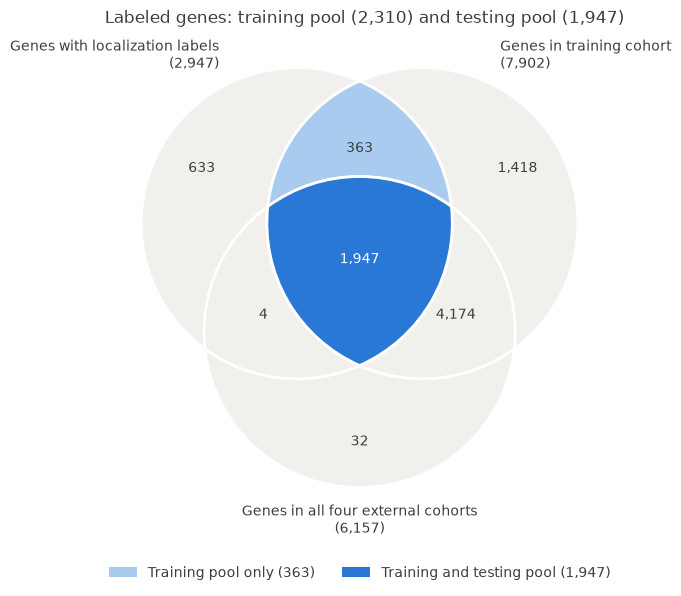

In [10]:
external_genes = set.intersection(*(set(genes[name]) for name in external))
INK = '#3d3d3a'
TRAIN_ONLY, TEST, OTHER = '#a9cbf0', '#2a78d6', '#f1f0ec'

fig, ax = plt.subplots(figsize=(7.5, 6.4))
# Number of genes in each region. Region ids: 1st digit = genes with localization labels, 2nd = training cohort, 3rd = all external cohorts.
sets = [set(curated.index), set(genes[training]), external_genes]
REGIONS = ['100', '010', '110', '001', '101', '011', '111']       # the order venn3 expects
counts = {r: len(set.intersection(*(s for s, d in zip(sets, r) if d == '1'))
                 - set().union(*(s for s, d in zip(sets, r) if d == '0'))) for r in REGIONS}
assert counts['110'] + counts['111'] == len(training_pool) and counts['111'] == len(testing_pool)

# Equal-sized circles (areas are not proportional to the counts) so that every region stays readable.
v = venn3(subsets=(1,) * 7,
          set_labels=(f'Genes with localization labels\n({len(curated):,})',
                      f'Genes in training cohort\n({len(genes[training]):,})',
                      f'Genes in all four external cohorts\n({len(external_genes):,})'), ax=ax)

for region in REGIONS:
    patch, label = v.get_patch_by_id(region), v.get_label_by_id(region)
    patch.set_facecolor({'110': TRAIN_ONLY, '111': TEST}.get(region, OTHER))
    patch.set_alpha(1); patch.set_edgecolor('white'); patch.set_linewidth(2)
    label.set_text(f'{counts[region]:,}')
    label.set_color('white' if region == '111' else INK); label.set_fontsize(10)
for label in v.set_labels:
    label.set_color(INK); label.set_fontsize(10)

handles = [plt.Rectangle((0, 0), 1, 1, facecolor=TRAIN_ONLY), plt.Rectangle((0, 0), 1, 1, facecolor=TEST)]
ax.legend(handles, [f'Training pool only ({len(training_pool) - len(testing_pool):,})',
                    f'Training and testing pool ({len(testing_pool):,})'],
          frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=10, labelcolor=INK)
ax.set_title(f'Labeled genes: training pool ({len(training_pool):,}) and testing pool ({len(testing_pool):,})',
             loc='left', color=INK, fontsize=12)
fig.savefig(label_path + 'label_pools_venn.pdf', bbox_inches='tight')
fig.savefig(label_path + 'label_pools_venn.png', dpi=300, bbox_inches='tight')
plt.show()

## Outputs

Written to `labels/`:

* `markers_curated.txt`: the curated markers (gene symbol, compartment), used as labels by every analysis.
* `marker_conflicts.tsv`: every removed marker with its Orre, MetaMass and HPA evidence, and which source it conflicts with.
* `label_curation_flow.csv`: number of markers after each curation step, in total and per compartment.
* `gene_localization_overlap.csv`: number of genes and labeled genes per cohort and per compartment, with the training and testing pools.
* `label_pools_venn.pdf` / `.png`: the Venn diagram above.

## Export

In [11]:
curated.rename_axis('Protein').rename('Localization').to_csv(Path(label_path + 'markers_curated.txt'), sep='\t')
conflicts.to_csv(Path(label_path + 'marker_conflicts.tsv'), sep='\t')
flow_df.to_csv(Path(label_path + 'label_curation_flow.csv'), index=False)
overlap.to_csv(Path(label_path + 'gene_localization_overlap.csv'), index=False)